#**📦 1. Install required libraries**

In [ ]:
!pip install kagglehub tensorflow matplotlib scikit-learn pandas --quiet

# **📁 2. Download dataset using kagglehub**

In [ ]:

import kagglehub
import os
import shutil

path = kagglehub.dataset_download("emmarex/plantdisease")
print("Dataset downloaded to:", path)

Dataset downloaded to: /kaggle/input/plantdisease


# **✅ 3. Unzip dataset if needed**

In [ ]:
import zipfile

dataset_zip = os.path.join(path, "plantdisease.zip")
extract_path = "/content/plant_disease_data"

if os.path.exists(dataset_zip):
    with zipfile.ZipFile(dataset_zip, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Dataset extracted to:", extract_path)
else:
    print("Zip file not found. Check dataset structure.")

Zip file not found. Check dataset structure.


# **✅ 4. Import libraries**

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# **✅ 5. Set up image parameters**

In [ ]:
img_height, img_width = 128, 128
batch_size = 32

# **✅ 6. Data generators with augmentation**

In [ ]:
import os, shutil
import random
from pathlib import Path

original_data_dir = "/kaggle/input/plantdisease/PlantVillage"
base_dir = "/content/split_plant_data"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "valid")

# Create folders
for split_dir in [train_dir, val_dir]:
    os.makedirs(split_dir, exist_ok=True)

# Split each class folder 80/20 into train/valid
for class_folder in os.listdir(original_data_dir):
    class_path = os.path.join(original_data_dir, class_folder)
    if not os.path.isdir(class_path):
        continue

    images = os.listdir(class_path)
    random.shuffle(images)

    split_idx = int(0.8 * len(images))
    train_imgs = images[:split_idx]
    val_imgs = images[split_idx:]

    # Create class subdirs
    os.makedirs(os.path.join(train_dir, class_folder), exist_ok=True)
    os.makedirs(os.path.join(val_dir, class_folder), exist_ok=True)

    # Move files
    for img in train_imgs:
        shutil.copy(os.path.join(class_path, img), os.path.join(train_dir, class_folder, img))
    for img in val_imgs:
        shutil.copy(os.path.join(class_path, img), os.path.join(val_dir, class_folder, img))

print("Train/Validation split complete.")

Train/Validation split complete.


# **✅ 7. Setup ImageDataGenerator**

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_height, img_width = 128, 128
batch_size = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2
)
val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical'
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

Found 16504 images belonging to 15 classes.
Found 4134 images belonging to 15 classes.


# **✅ 8. Build CNN model**

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(img_height, img_width, 3)),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(train_gen.num_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# **✅ 9. Train model**

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(patience=3, restore_best_weights=True)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    callbacks=[early_stop]
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 513s 991ms/step - accuracy: 0.4404 - loss: 1.8122 - val_accuracy: 0.7165 - val_loss: 0.8535
Epoch 2/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 489s 947ms/step - accuracy: 0.7543 - loss: 0.7229 - val_accuracy: 0.7397 - val_loss: 0.8333
Epoch 3/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 484s 937ms/step - accuracy: 0.8333 - loss: 0.4922 - val_accuracy: 0.8331 - val_loss: 0.5370
Epoch 4/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 471s 913ms/step - accuracy: 0.8652 - loss: 0.3933 - val_accuracy: 0.8299 - val_loss: 0.5787
Epoch 5/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 470s 911ms/step - accuracy: 0.8838 - loss: 0.3468 - val_accuracy: 0.7617 - val_loss: 0.9658
Epoch 6/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 481s 932ms/step - accuracy: 0.8939 - loss: 0.3106 - val_accuracy: 0.8832 - val_loss: 0.4106
Epoch 7/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 475s 920ms/step - accuracy: 0.9034 - loss: 0.2878 - val_accuracy: 0.8938 - val_loss: 0.3627
Epoch 8/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 474s 918ms/step - accuracy: 0.9168 -

# **✅ 10. Evaluate performance**

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

val_gen.reset()
y_pred = model.predict(val_gen)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = val_gen.classes
class_labels = list(val_gen.class_indices.keys())

print(classification_report(y_true, y_pred_classes, target_names=class_labels))

130/130 ━━━━━━━━━━━━━━━━━━━━ 31s 237ms/step
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.92      0.85      0.89       200
                     Pepper__bell___healthy       0.94      0.98      0.96       296
                      Potato___Early_blight       0.86      0.98      0.92       200
                       Potato___Late_blight       0.93      0.81      0.87       200
                           Potato___healthy       0.63      0.77      0.70        31
                      Tomato_Bacterial_spot       0.95      0.93      0.94       426
                        Tomato_Early_blight       0.68      0.80      0.74       200
                         Tomato_Late_blight       0.90      0.82      0.86       382
                           Tomato_Leaf_Mold       0.97      0.82      0.89       191
                  Tomato_Septoria_leaf_spot       0.89      0.86      0.88       355
Tomato_Spider_mites_

# **✅ 11. Confusion matrix**

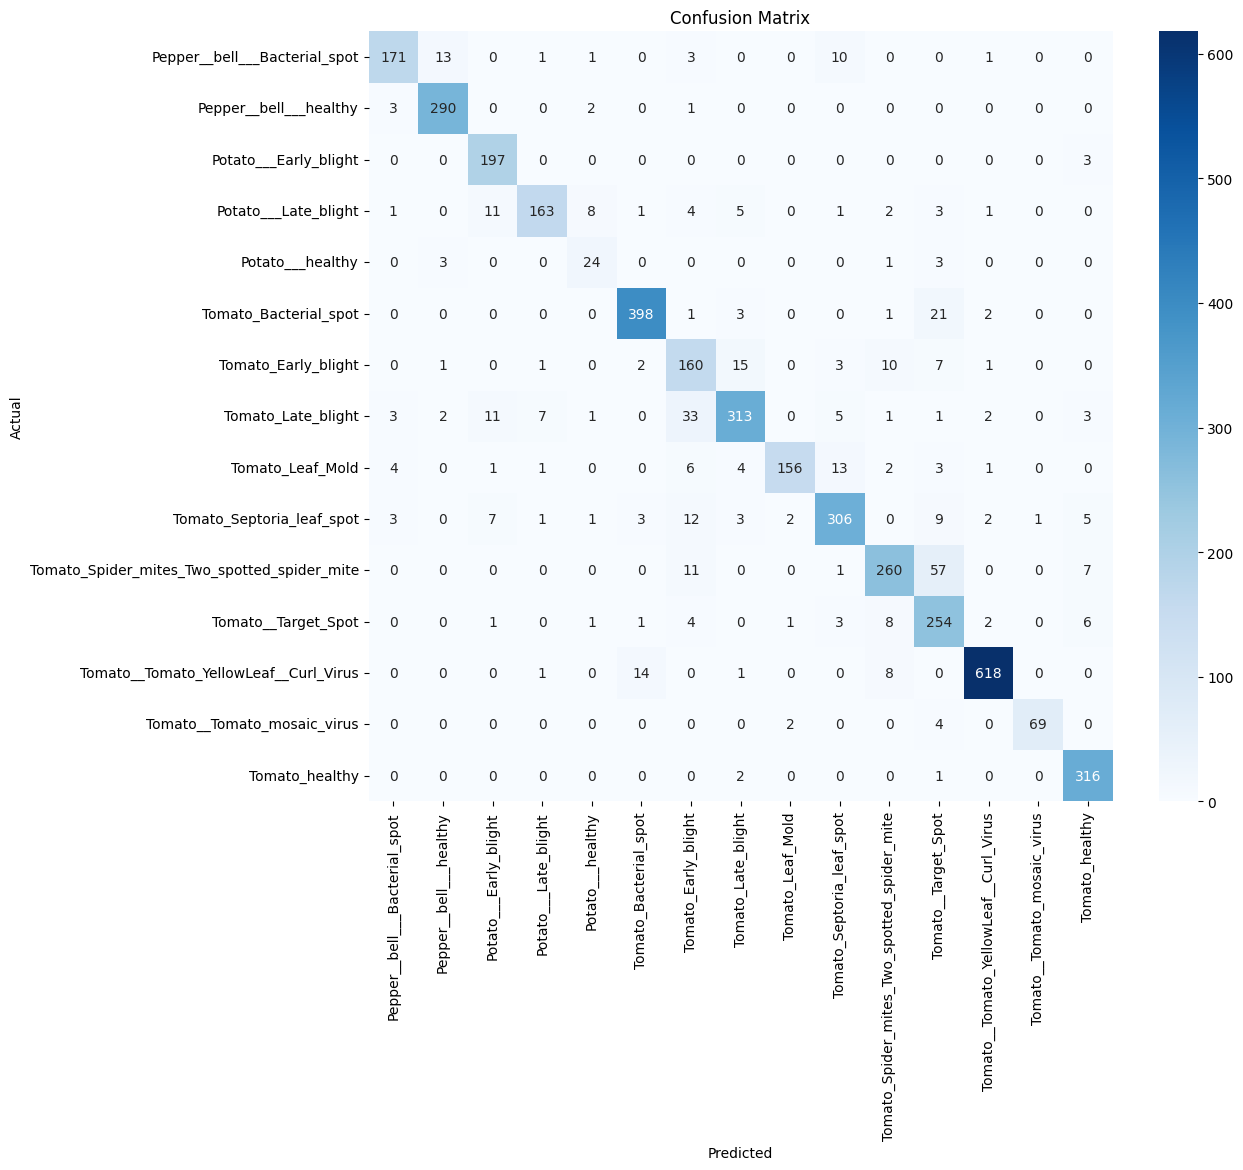

In [ ]:
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.title("Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

# **✅ 12. Export metrics for Power BI**

In [ ]:
report = classification_report(y_true, y_pred_classes, target_names=class_labels, output_dict=True)
df_report = pd.DataFrame(report).transpose()
df_report.to_csv("classification_metrics.csv")
print("✅ Saved: classification_metrics.csv")

✅ Saved: classification_metrics.csv


# **✅ 13. Show misclassified images**

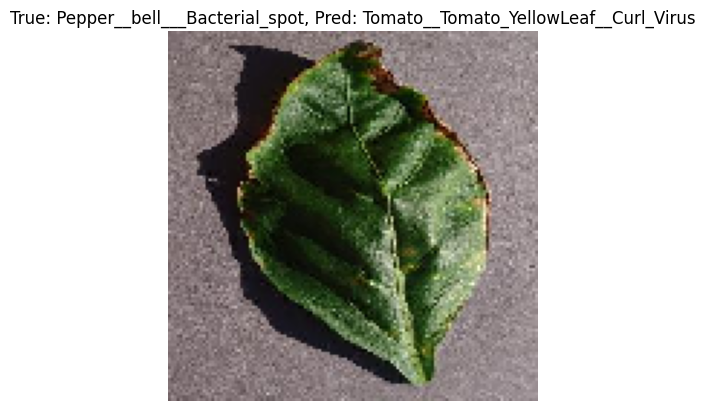

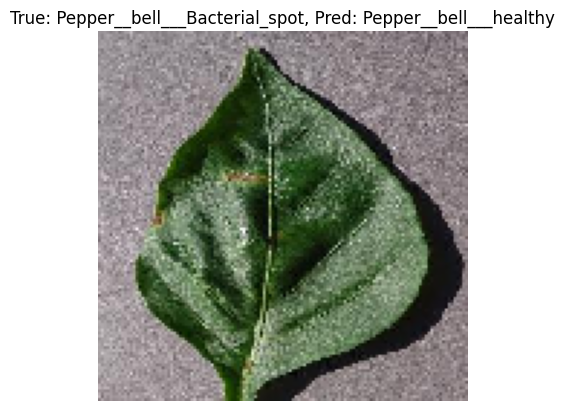

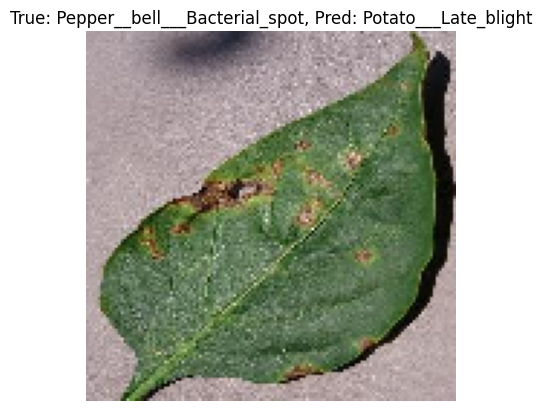

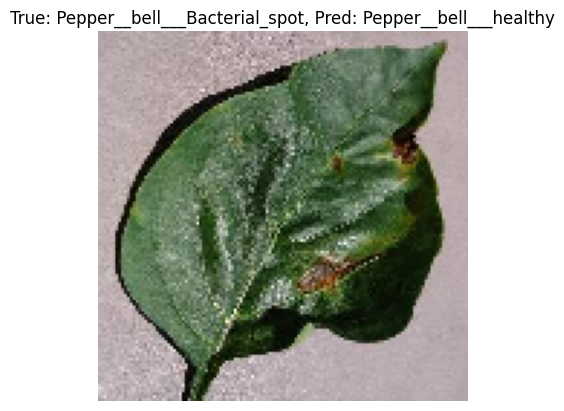

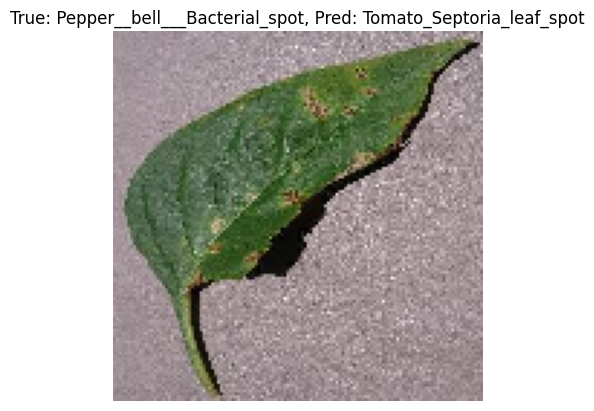

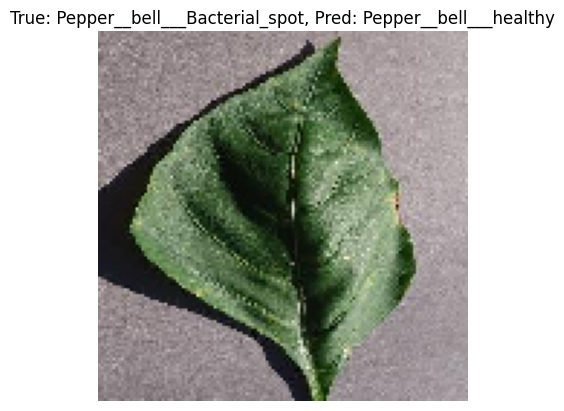

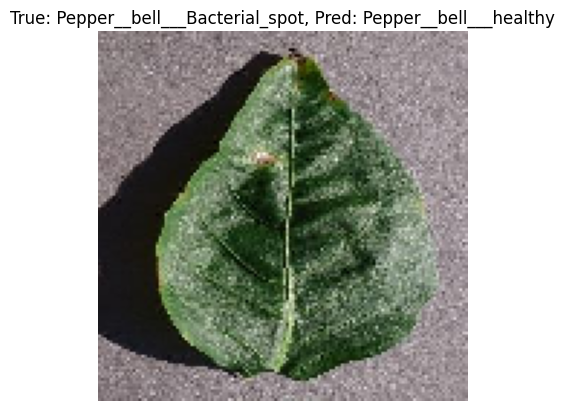

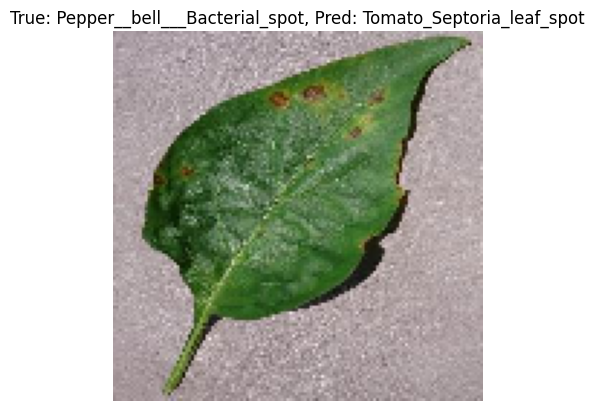

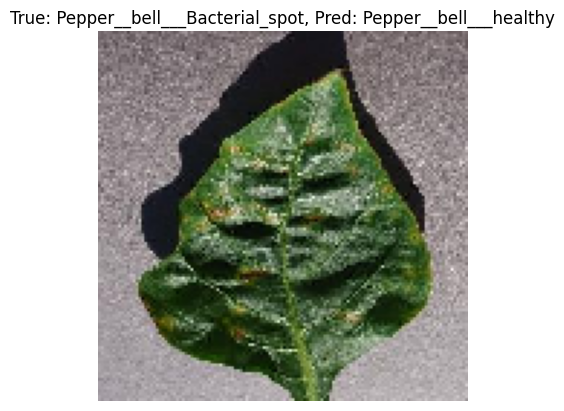

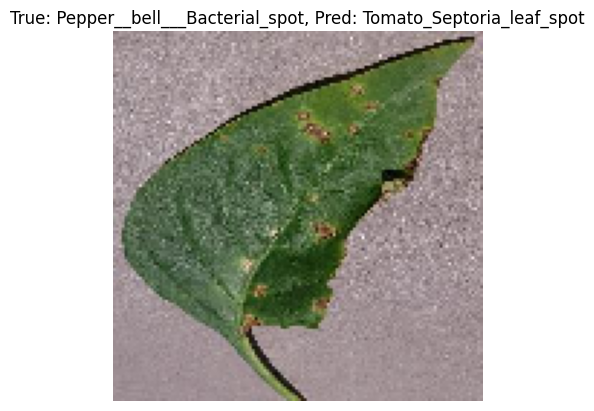

In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

misclassified_indices = np.where(y_pred_classes != y_true)[0]
val_filepaths = val_gen.filepaths

for idx in misclassified_indices[:10]:  # Show first 10 misclassified
    img_path = val_filepaths[idx]
    img = load_img(img_path, target_size=(img_height, img_width))
    img_arr = img_to_array(img) / 255.0

    plt.imshow(img_arr)
    plt.title(f"True: {class_labels[y_true[idx]]}, Pred: {class_labels[y_pred_classes[idx]]}")
    plt.axis('off')
    plt.show()

# **✅ 14. Save model (optional)**

In [ ]:
model.save("plant_disease_model.h5")
print("✅ Model saved to plant_disease_model.h5")

✅ Model saved to plant_disease_model.h5


# **14. confusion_matrix.csv**

In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(y_true, y_pred_classes)
cm_df = pd.DataFrame(cm, index=class_labels, columns=class_labels)
cm_df.reset_index(inplace=True)
cm_df.rename(columns={"index": "Actual"}, inplace=True)
cm_df.to_csv("confusion_matrix.csv", index=False)
print("✅ confusion_matrix.csv exported")


✅ confusion_matrix.csv exported


# **15. predictions.csv (Optional)**

In [ ]:
import os

samples = []
val_filepaths = val_gen.filepaths

for idx in range(len(y_true)):
    filename = os.path.basename(val_filepaths[idx])
    true_lbl = class_labels[y_true[idx]]
    pred_lbl = class_labels[y_pred_classes[idx]]
    samples.append([filename, true_lbl, pred_lbl])

df_pred = pd.DataFrame(samples, columns=['filename', 'true_label', 'predicted_label'])
df_pred.to_csv("predictions.csv", index=False)
print("✅ predictions.csv exported")


✅ predictions.csv exported


In [ ]:
import json

# Save class indices from the training generator
with open("class_indices.json", "w") as f:
    json.dump(train_gen.class_indices, f)

print("✅ class_indices.json saved!")


✅ class_indices.json saved!


In [ ]:
from google.colab import files
files.download("class_indices.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 0. If you still have the training history 'history' object:
import pandas as pd, numpy as np

hist_df = pd.DataFrame(history.history)
hist_df['epoch'] = np.arange(1, len(hist_df)+1)
# (rename columns if needed)
# hist_df.columns = ['loss','accuracy','val_loss','val_accuracy','epoch']
hist_df.to_csv('history.csv', index=False)

# 1. If you computed predictions on val_gen earlier:
#    val_gen, y_true, y_pred_classes, y_pred (probabilities), class_labels, and val_gen.filepaths
import os

probs = y_pred.max(axis=1)
sample_df = pd.DataFrame({
    'file_name': [os.path.basename(p) for p in val_gen.filepaths],
    'true_label': [class_labels[i] for i in y_true],
    'predicted_label': [class_labels[i] for i in y_pred_classes],
    'confidence': probs
})
sample_df.to_csv('sample_predictions.csv', index=False)


In [ ]:
import os
import shutil
import pandas as pd
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Create output folder
output_dir = "sample_images"
os.makedirs(output_dir, exist_ok=True)

sample_data = []

# Take 10 misclassified + 10 correctly classified
misclassified = np.where(y_pred_classes != y_true)[0][:10]
correct = np.where(y_pred_classes == y_true)[0][:10]
indices = np.concatenate([misclassified, correct])

for idx in indices:
    file_path = val_filepaths[idx]
    file_name = os.path.basename(file_path)

    true = class_labels[y_true[idx]]
    pred = class_labels[y_pred_classes[idx]]
    conf = round(100 * np.max(y_pred[idx]), 2)

    # Copy image into sample_images folder
    shutil.copy(file_path, os.path.join(output_dir, file_name))

    # Append to table
    sample_data.append([file_name, true, pred, conf])

# Save CSV
df_samples = pd.DataFrame(sample_data, columns=["file_name", "true_label", "predicted_label", "confidence"])
df_samples.to_csv("sample_predictions.csv", index=False)

print("✅ Exported sample images to", output_dir)
print("✅ CSV saved as sample_predictions.csv")


✅ Exported sample images to sample_images
✅ CSV saved as sample_predictions.csv


In [ ]:
import shutil

# Create a zip archive of the sample_images folder
shutil.make_archive("sample_images", 'zip', "sample_images")

print("✅ sample_images.zip created!")

✅ sample_images.zip created!


In [ ]:
from google.colab import files

files.download("sample_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>